# 06 · Neue Zeitreihen und mehr Foundation Models

- **Daten:** stündliche RV für Gold (PAXG), Euro/Dollar (EUR/USDT) und zwei neue Kryptos (XRP, BNB), wieder aus Binance-1-Min-Kerzen
- **Neue Foundation Models:** TiRex (xLSTM, rekurrent) und FlowState (State-Space-Modell), beide kein Transformer
- **Gate:** nur die Zeitreihe selbst (letzte 24 Werte) und die Uneinigkeit der Experten, keine exogenen Features
- **Pools:** 2 FMs (alt) / 4 FMs / 4 FMs + HAR + GARCH

Einmalig installieren: `pip install tirex-ts granite-tsfm`. Alle Ergebnisse landen in eigenen Ordnern, die alten Läufe bleiben unberührt.

In [2]:
import json, time, zipfile
from functools import partial
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

from pipeline import common as C, experts as ex, features as F, combine as cb

DATASET = "binance_1h_neu"
SYMBOLS = ["PAXGUSDT", "EURUSDT", "XRPUSDT", "BNBUSDT"]   # Gold, Euro/Dollar, zwei neue Kryptos
FIRST_MONTH, LAST_MONTH = "2024-07", "2026-02"            # nichts ab März 2026: Testperiode bleibt zu
MIN_BARS = 54                                             # von 60 Minuten, sonst Stunde verwerfen

C.ORIGIN_START = "2025-01-01"
EVAL_START, EVAL_END, TUNE_DAYS = "2025-11-01", "2026-02-28", 90

FMS = ["Chronos-2-full", "TimesFM-2.5", "TiRex", "FlowState"]
MODELS = ["RW", "HAR", "GARCH"] + FMS
POOLS = {
    "2 FMs (alt)": ["Chronos-2-full", "TimesFM-2.5"],
    "4 FMs": FMS,
    "4 FMs + HAR/GARCH": FMS + ["HAR", "GARCH"],
}
RAW_LAGS = 24                                             # Gate sieht die letzten 24 Stunden log-RV
LAMBDAS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

DATA_DIR = Path("data") / DATASET
FC_DIR = Path("results") / "forecasts" / DATASET
C.FM_BATCH = 512
FC_DIR = Path("/content/drive/MyDrive/bachelorprojekt/forecasts") / DATASET
FC_DIR.mkdir(parents=True, exist_ok=True)

## 1 · Daten

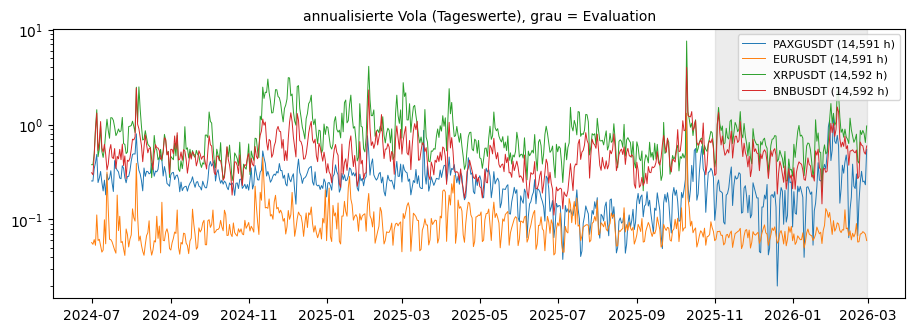

In [6]:
URL = "https://data.binance.vision/data/spot/monthly/klines/{s}/1m/{s}-1m-{ym}.zip"


def month_close(sym, ym):
    path = Path("data") / "raw" / sym / f"{sym}-1m-{ym}.zip"      # gleicher Cache wie 01
    if not path.exists():
        import requests
        r = requests.get(URL.format(s=sym, ym=ym), timeout=60)
        if r.status_code in (403, 404):
            return None
        r.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(r.content)
    with zipfile.ZipFile(path) as zf, zf.open(zf.namelist()[0]) as f:
        df = pd.read_csv(f, header=None, usecols=[0, 4])
    df = df[pd.to_numeric(df[0], errors="coerce").notna()]           # evtl. Kopfzeile
    t = df[0].astype("int64").to_numpy()
    return pd.Series(df[4].astype(float).to_numpy(), index=pd.to_datetime(t, unit="us" if t.max() > 1e14 else "ms"))


def hourly_rv(sym):
    path = DATA_DIR / f"{sym}_daily.parquet"                          # Name wie in 01, damit 02-05 es auch lesen
    if path.exists():
        return pd.read_parquet(path)
    months = pd.period_range(FIRST_MONTH, LAST_MONTH, freq="M").strftime("%Y-%m")
    close = pd.concat([c for ym in months if (c := month_close(sym, ym)) is not None]).sort_index()
    r = np.log(close[~close.index.duplicated()]).diff().dropna()
    hour = r.index.floor("1h")
    d = pd.DataFrame({"rv": (r ** 2).groupby(hour).sum(), "ret": r.groupby(hour).sum(), "n_bars": r.groupby(hour).size()})
    d = d[(d["n_bars"] >= MIN_BARS) & (d["rv"] > 0)].rename_axis("date")
    path.parent.mkdir(parents=True, exist_ok=True)
    d.to_parquet(path)
    return d


daily = {s: hourly_rv(s) for s in SYMBOLS}
Path("data").mkdir(exist_ok=True)
(Path("data") / f"{DATASET}.json").write_text(json.dumps(
    {"name": DATASET, "sids": SYMBOLS, "daily_dir": str(DATA_DIR), "forecast_dir": str(FC_DIR),
     "test_start": "2026-03-01", "info": {"source": "binance", "interval": "1m", "min_bars": MIN_BARS}}, indent=2))

fig, ax = plt.subplots(figsize=(11, 3.5))
for s, d in daily.items():
    ax.plot(np.sqrt(365 * d["rv"].resample("D").sum()), lw=0.7, label=f"{s} ({len(d):,} h)")
ax.set_yscale("log")
ax.axvspan(pd.Timestamp(EVAL_START), pd.Timestamp(EVAL_END), color="grey", alpha=0.15)
ax.set_title("annualisierte Vola (Tageswerte), grau = Evaluation", fontsize=10)
ax.legend(fontsize=8)
plt.show()

## 2 · Experten

TiRex und FlowState liefern wie TimesFM die Quantile 0.1 bis 0.9, die übrigen ergänzt `expand_quantiles` aus `experts.py`.
Fertige Prognosen werden gecacht, ein zweiter Lauf rechnet nur Fehlendes.

In [14]:
def from_log9(logq9):
    # (n, H, 9) Log-Quantile 0.1..0.9 -> Mittelwert und 21 Quantile auf RV-Skala, wie TimesFM in experts.py
    logq9 = np.sort(np.asarray(logq9, float)[:, [h - 1 for h in C.HORIZONS], :], axis=-1)
    q = np.sort(np.exp(ex.expand_quantiles(logq9)), axis=-1)
    return C.mean_from_quantiles(q), q


class TiRex(ex.Expert):
    """NX-AI, Mai 2025, 35M Parameter. xLSTM: liest die Reihe rekurrent statt mit Attention."""
    name = "TiRex"

    def __init__(self, chunk=1024):
        from tirex import load_model
        self.chunk = chunk
        self.model = load_model("NX-AI/TiRex", backend="torch", device=ex._device())

    def forecast(self, s, origins):
        ctx = np.stack(ex.contexts_for(s, origins))                     # (n, 1024) log-RV
        parts = []
        for k in tqdm(range(0, len(ctx), self.chunk), desc=f"TiRex {s.sid}", leave=False):
            q, _ = self.model.forecast(context=ctx[k:k + self.chunk], prediction_length=max(C.HORIZONS),
                                       output_type="numpy", batch_size=256)
            parts.append(q)                                              # (B, H, 9)
        return from_log9(np.concatenate(parts))


class FlowState(ex.Expert):
    """IBM, 2025, 9M Parameter. State-Space-Encoder (S5) + funktionaler Basis-Decoder.
    Version r1 (ohne revision), r1.1 ist neuer und könnte unsere Evaluationsdaten gesehen haben.
    scale_factor 1.0 = Stundendaten mit Tageszyklus (laut Modellkarte)."""
    name = "FlowState"

    def __init__(self, batch=64, scale_factor=1.0):
        from tsfm_public import FlowStateForPrediction
        self.batch, self.scale = batch, scale_factor
        self.model = (FlowStateForPrediction.from_pretrained("ibm-granite/granite-timeseries-flowstate-r1")
                      .to(ex._device()).eval())                                        # <- GPU

    def forecast(self, s, origins):
        ctx = np.stack(ex.contexts_for(s, origins))
        parts = []
        for k in tqdm(range(0, len(ctx), self.batch), desc=f"FlowState {s.sid}", leave=False):
            x = torch.from_numpy(ctx[k:k + self.batch])[:, :, None].to(ex._device())  # <- GPU
            with torch.no_grad():
                out = self.model(x, scale_factor=self.scale, prediction_length=max(C.HORIZONS), batch_first=True)
            parts.append(out.quantile_outputs[..., 0].cpu().numpy().transpose(0, 2, 1))   # <- .cpu()
        return from_log9(np.concatenate(parts))


EXPERTS = {**ex.EXPERTS, "TiRex": TiRex, "FlowState": FlowState}
series = {s: ex.RVSeries(s, daily[s]) for s in SYMBOLS}
print({s: len(x.origins) for s, x in series.items()}, "Ursprünge")

FC_DIR.mkdir(parents=True, exist_ok=True)

for m in MODELS:
    todo = [s for s in SYMBOLS if not (FC_DIR / f"{s}__{m}.parquet").exists()]
    if not todo:
        print(f"{m:>15} | gecacht")
        continue
    try:
        expert = EXPERTS[m]()
    except ImportError as e:
        print(f"{m:>15} | übersprungen, Paket fehlt ({e.name})")
        continue
    for sid in todo:
        t0, s = time.time(), series[sid]
        mean, q = expert.forecast(s, s.origins)
        ex.forecast_frame(m, s, s.origins, mean, q).to_parquet(FC_DIR / f"{sid}__{m}.parquet")
        print(f"{m:>15} | {sid}: {time.time() - t0:.0f}s")
    del expert

{'PAXGUSDT': 10151, 'EURUSDT': 10152, 'XRPUSDT': 10152, 'BNBUSDT': 10152} Ursprünge
             RW | gecacht
            HAR | gecacht
          GARCH | gecacht
 Chronos-2-full | gecacht
    TimesFM-2.5 | gecacht
          TiRex | gecacht


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

FlowState PAXGUSDT:   0%|          | 0/159 [00:00<?, ?it/s]

      FlowState | PAXGUSDT: 113s


FlowState EURUSDT:   0%|          | 0/159 [00:00<?, ?it/s]

      FlowState | EURUSDT: 112s


FlowState XRPUSDT:   0%|          | 0/159 [00:00<?, ?it/s]

      FlowState | XRPUSDT: 112s


FlowState BNBUSDT:   0%|          | 0/159 [00:00<?, ?it/s]

      FlowState | BNBUSDT: 112s


## 3 · Wie gut sind die einzelnen Experten? (Evaluation Nov 25 – Feb 26)

In [15]:
fc_all = pd.concat([pd.read_parquet(p) for p in sorted(FC_DIR.glob("*__*.parquet"))], ignore_index=True)
MODELS = [m for m in MODELS if m in set(fc_all["model"])]
POOLS = {k: [m for m in v if m in MODELS] for k, v in POOLS.items()}
print("Pools:", POOLS)

ev = fc_all[(fc_all["target_date"] >= EVAL_START) & (fc_all["target_date"] < pd.Timestamp(EVAL_END) + pd.Timedelta(days=1))].copy()
ev["qlike"] = C.qlike(ev["y"], ev["mean"])
ev["logerr"] = np.log(ev["y"] / ev["mean"])

q = ev.pivot_table(index=["h", "sid"], columns="model", values="qlike")[MODELS]
print("QLIKE relativ zum Random Walk (< 1 = besser)")
display(q.div(q["RW"], axis=0).round(3))

for h in C.HORIZONS:
    E = ev[ev["h"] == h].pivot_table(index=["sid", "origin"], columns="model", values="logerr")
    print(f"h={h}: Korrelation der Log-Fehler")
    display(E[[m for m in MODELS if m != "RW"]].corr().round(2))

Pools: {'2 FMs (alt)': ['Chronos-2-full', 'TimesFM-2.5'], '4 FMs': ['Chronos-2-full', 'TimesFM-2.5', 'TiRex', 'FlowState'], '4 FMs + HAR/GARCH': ['Chronos-2-full', 'TimesFM-2.5', 'TiRex', 'FlowState', 'HAR', 'GARCH']}
QLIKE relativ zum Random Walk (< 1 = besser)


model         RW    HAR  GARCH  Chronos-2-full  TimesFM-2.5  TiRex  FlowState
h  sid                                                                       
1  BNBUSDT   1.0  0.915  1.382           0.754        0.772  0.746      0.801
   EURUSDT   1.0  1.254  3.058           0.421        0.428  0.425      0.436
   PAXGUSDT  1.0  0.317  0.302           0.159        0.161  0.152      0.202
   XRPUSDT   1.0  0.947  1.512           0.776        0.835  0.768      0.836
24 BNBUSDT   1.0  0.846  1.099           0.755        0.707  0.768      0.790
   EURUSDT   1.0  0.988  1.852           0.169        0.170  0.173      0.176
   PAXGUSDT  1.0  0.178  0.213           0.193        0.210  0.207      0.229
   XRPUSDT   1.0  0.812  0.796           0.544        0.572  0.545      0.633

h=1: Korrelation der Log-Fehler


model,HAR,GARCH,Chronos-2-full,TimesFM-2.5,TiRex,FlowState
model,,,,,,
HAR,1.00,0.44,0.81,0.85,0.80,0.82
GARCH,0.44,1.00,0.37,0.40,0.37,0.37
Chronos-2-full,0.81,0.37,1.00,0.96,0.97,0.96
TimesFM-2.5,0.85,0.40,0.96,1.00,0.97,0.96
TiRex,0.80,0.37,0.97,0.97,1.00,0.96
FlowState,0.82,0.37,0.96,0.96,0.96,1.00


h=24: Korrelation der Log-Fehler


model,HAR,GARCH,Chronos-2-full,TimesFM-2.5,TiRex,FlowState
model,,,,,,
HAR,1.00,0.58,0.71,0.75,0.72,0.74
GARCH,0.58,1.00,0.45,0.48,0.46,0.48
Chronos-2-full,0.71,0.45,1.00,0.93,0.95,0.94
TimesFM-2.5,0.75,0.48,0.93,1.00,0.95,0.94
TiRex,0.72,0.46,0.95,0.95,1.00,0.96
FlowState,0.74,0.48,0.94,0.94,0.96,1.00


## 4 · Gate nur auf Zeitreihe + Disagree

- `raw`: log-RV der letzten 24 Stunden, relativ zum Wochenmittel (wie das Mean-Scaling der FMs)
- `disagree`: Abweichung jedes Experten vom Mittel der Experten
- Walk-Forward wie in 04: monatliches Neutraining, λ auf den letzten 90 Tagen gewählt

In [16]:
def raw_features(d):
    lrv = np.log(d["rv"])
    norm = np.log(d["rv"].rolling(7 * 24).mean())
    f = pd.DataFrame({f"raw_{i}": lrv.shift(i) - norm for i in range(RAW_LAGS)})
    f["scale"] = d["rv"].rolling(22 * 24).mean()                      # nur für den Pinball-Term im Loss
    return f


daily_feat = pd.concat({s: raw_features(daily[s]) for s in SYMBOLS}, names=["sid", "origin"])


def make_panels(pool):
    cfg = F.FeatureConfig(pool, SYMBOLS, groups=["market", "disagree"], calendar=[])
    fc = F.add_recent(fc_all[fc_all["model"].isin(pool)], cfg)
    panels = {}
    for h in C.HORIZONS:
        df, groups = F.build_panel(fc, daily_feat, h, cfg)       # "market" = hier nur die raw_*-Spalten
        groups = {("raw" if g == "market" else g): v for g, v in groups.items()}
        panels[h] = cb.Panel(df, h, pool, groups)
    return panels


METHODS = [
    cb.Method("Gleichgewicht", cb.Equal),
    cb.Method("Auswahl", cb.BestSingle),
    cb.Method("Statisch", partial(cb.Gate, groups=())),
    cb.Method("Gate linear", cb.Gate, {"lam": LAMBDAS}),
    cb.Method("Gate linear [nur disagree]", partial(cb.Gate, groups=("disagree",)), {"lam": LAMBDAS}),
    cb.Method("Gate MLP", partial(cb.Gate, hidden=16), {"lam": LAMBDAS}),
]

rows, wts = [], []
t0 = time.time()
for pool_name, pool in POOLS.items():
    for h, P in make_panels(pool).items():
        for fold in cb.walkforward_folds(P, EVAL_START, EVAL_END, "MS", TUNE_DAYS):
            Pt = P.take(fold.test)
            base = Pt.meta[["sid", "h", "target_date", "y"]].assign(pool=pool_name, fold=fold.label)
            for j, m in enumerate(pool):
                rows.append(base.assign(model=m, mean=Pt.mean[:, j]))
            for method in METHODS:
                c, best, _ = cb.fit_predict(P, method, fold)
                w = c.weights(Pt)
                rows.append(base.assign(model=method.name, mean=(w * Pt.mean).sum(1)))
                wts.append(pd.DataFrame(w, columns=pool).assign(pool=pool_name, h=h, model=method.name))
        print(f"{pool_name:<20} h={h:<3} fertig ({time.time() - t0:.0f}s)")

res = pd.concat(rows, ignore_index=True)
res["qlike"] = C.qlike(res["y"], res["mean"])
wts = pd.concat(wts, ignore_index=True)

2 FMs (alt)          h=1   fertig (118s)
2 FMs (alt)          h=24  fertig (210s)
4 FMs                h=1   fertig (385s)
4 FMs                h=24  fertig (532s)
4 FMs + HAR/GARCH    h=1   fertig (783s)
4 FMs + HAR/GARCH    h=24  fertig (1062s)


## 5 · Ergebnisse

Vergleich mit dem besten Einzelexperten des jeweiligen Pools (ex post). Negativ = besser.
p: Diebold-Mariano auf dem stündlichen Mittel über die Serien (Newey-West, Lag max(h−1, 24)).

In [17]:
def dm_p(d, h):
    d = d[np.isfinite(d)]
    T, u, L = len(d), d - d.mean(), max(h - 1, 24)
    var = u @ u / T + 2 * sum((1 - l / (L + 1)) * (u[l:] @ u[:-l]) / T for l in range(1, L + 1))
    return 2 * (1 - NormalDist().cdf(abs(d.mean() / np.sqrt(var / T))))


out = []
for (pool_name, h), g in res.groupby(["pool", "h"], sort=False):
    L = g.pivot_table(index="target_date", columns="model", values="qlike")
    best = L[POOLS[pool_name]].mean().idxmin()
    for m in L.columns:
        out.append({"Pool": pool_name, "Modell": m, "h": h, "QLIKE": L[m].mean(),
                    "Δ % vs. bester": 100 * (L[m].mean() / L[best].mean() - 1),
                    "p": np.nan if m == best else dm_p((L[m] - L[best]).to_numpy(), h)})
    print(f"{pool_name:<20} h={h:<3} bester Experte: {best}")

S = pd.DataFrame(out)
order = list(dict.fromkeys(MODELS + [m.name for m in METHODS]))
S["Modell"] = pd.Categorical(S["Modell"], order)
S["Pool"] = pd.Categorical(S["Pool"], list(POOLS))
display(S.pivot_table(index=["Pool", "Modell"], columns="h", values=["Δ % vs. bester", "p"], observed=True).round(3))

2 FMs (alt)          h=1   bester Experte: Chronos-2-full
2 FMs (alt)          h=24  bester Experte: Chronos-2-full
4 FMs                h=1   bester Experte: TiRex
4 FMs                h=24  bester Experte: Chronos-2-full
4 FMs + HAR/GARCH    h=1   bester Experte: TiRex
4 FMs + HAR/GARCH    h=24  bester Experte: Chronos-2-full


/tmp/ipykernel_49/1020535929.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * (1 - NormalDist().cdf(abs(d.mean() / np.sqrt(var / T))))
/tmp/ipykernel_49/1020535929.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * (1 - NormalDist().cdf(abs(d.mean() / np.sqrt(var / T))))
/tmp/ipykernel_49/1020535929.py:5: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * (1 - NormalDist().cdf(abs(d.mean() / np.sqrt(var / T))))


p        Δ % vs. bester  \
h                                                1      24             1    
Pool              Modell                                                    
2 FMs (alt)       Chronos-2-full                NaN    NaN          0.000   
                  TimesFM-2.5                 0.124  0.332          2.998   
                  Gleichgewicht               0.611  0.702         -0.586   
                  Auswahl                       NaN    NaN          0.000   
                  Statisch                    0.124  0.332          2.998   
                  Gate linear                 0.477  0.655          0.649   
                  Gate linear [nur disagree]  0.099  0.825          1.392   
                  Gate MLP                    0.854  0.679         -0.261   
4 FMs             Chronos-2-full              0.280    NaN          2.314   
                  TimesFM-2.5                 0.005  0.332          5.381   
                  TiRex                         NaN  0.246          0.000   
                  FlowState                   0.023  0.010         17.282   
                  Gleichgewicht               0.448  0.895          0.677   
                  Auswahl                     0.280    NaN          2.314   
                  Statisch                    0.837  0.468          0.087   
                  Gate linear                 0.256  0.523          1.640   
                  Gate linear [nur disagree]  0.242  0.895          2.000   
                  Gate MLP                    0.354  0.826          3.748   
4 FMs + HAR/GARCH HAR                         0.000  0.107         76.484   
                  GARCH                       0.000  0.001        152.931   
                  Chronos-2-full              0.280    NaN          2.314   
                  TimesFM-2.5                 0.005  0.332          5.381   
                  TiRex                         NaN  0.246          0.000   
                  FlowState                   0.023  0.010         17.282   
                  Gleichgewicht               0.052  0.603         36.964   
                  Auswahl                     0.000  0.000         66.851   
                  Statisch                    0.000  0.238         32.572   
                  Gate linear                 0.055  0.013         36.621   
                  Gate linear [nur disagree]  0.056  0.735         36.529   
                  Gate MLP                    0.120  0.168         17.988   

                                                      
h                                                 24  
Pool              Modell                              
2 FMs (alt)       Chronos-2-full               0.000  
                  TimesFM-2.5                  4.285  
                  Gleichgewicht               -0.875  
                  Auswahl                      0.000  
                  Statisch                     4.285  
                  Gate linear                  0.536  
                  Gate linear [nur disagree]   0.198  
                  Gate MLP                     1.617  
4 FMs             Chronos-2-full               0.000  
                  TimesFM-2.5                  4.285  
                  TiRex                        4.299  
                  FlowState                   14.452  
                  Gleichgewicht                0.364  
                  Auswahl                      0.000  
                  Statisch                     2.855  
                  Gate linear                  0.822  
                  Gate linear [nur disagree]  -0.465  
                  Gate MLP                     0.623  
4 FMs + HAR/GARCH HAR                         35.583  
                  GARCH                       77.900  
                  Chronos-2-full               0.000  
                  TimesFM-2.5                  4.285  
                  TiRex                        4.299  
                  FlowState                   14.452  
                  Gleic

In [18]:
# Pro Serie: Gold und Euro gegen die Kryptos. Δ % vs. bester Experte des Pools auf dieser Serie
out = []
for (pool_name, h, sid), g in res.groupby(["pool", "h", "sid"], sort=False):
    Lm = g.groupby("model")["qlike"].mean()
    best = Lm[POOLS[pool_name]].min()
    for m in ["Statisch", "Gate linear", "Gate MLP"]:
        out.append({"Pool": pool_name, "Serie": sid, "h": h, "Modell": m, "Δ %": 100 * (Lm[m] / best - 1)})
display(pd.DataFrame(out).pivot_table(index=["Pool", "Serie"], columns=["h", "Modell"], values="Δ %").round(2))

h                                1                             24              \
Modell                     Gate MLP Gate linear Statisch Gate MLP Gate linear   
Pool              Serie                                                         
2 FMs (alt)       BNBUSDT      0.24        0.26     2.47    -0.73        4.81   
                  EURUSDT     -0.21       -0.03     1.63    -0.14       -0.15   
                  PAXGUSDT    -0.91       -0.19     1.09     5.12        1.52   
                  XRPUSDT      0.32        2.82     7.50     2.74        0.78   
4 FMs             BNBUSDT      0.64        0.85     0.12     0.72        7.77   
                  EURUSDT     -1.22       -0.11     0.43     1.76       -0.44   
                  PAXGUSDT     9.96        2.80    -0.21     2.97        1.20   
                  XRPUSDT     -0.67        1.82     0.87     1.30        0.09   
4 FMs + HAR/GARCH BNBUSDT     -1.40        3.14     7.73     3.07        9.59   
                  EURUSDT    151.20      290.15   178.04   146.23       16.05   
                  PAXGUSDT     5.03        8.21    22.67    11.74       16.41   
                  XRPUSDT     -1.18        2.46     8.33    -0.96        3.09   

h                                    
Modell                     Statisch  
Pool              Serie              
2 FMs (alt)       BNBUSDT      0.00  
                  EURUSDT      0.62  
                  PAXGUSDT     8.93  
                  XRPUSDT      5.29  
4 FMs             BNBUSDT      1.48  
                  EURUSDT      0.92  
                  PAXGUSDT     6.23  
                  XRPUSDT      3.48  
4 FMs + HAR/GARCH BNBUSDT     10.66  
                  EURUSDT    480.66  
                  PAXGUSDT   -11.82  
                  XRPUSDT     32.06

In [19]:
# Mittlere Gewichte: wer bekommt wie viel?
for pool_name, pool in POOLS.items():
    w = wts[(wts["pool"] == pool_name) & wts["model"].isin(["Statisch", "Gate linear", "Gate MLP"])]
    print(pool_name)
    display(w.groupby(["h", "model"])[pool].mean().round(3))

2 FMs (alt)


Chronos-2-full  TimesFM-2.5
h  model                                   
1  Gate MLP              0.624        0.376
   Gate linear           0.511        0.489
   Statisch              0.000        1.000
24 Gate MLP              0.173        0.827
   Gate linear           0.703        0.297
   Statisch              0.000        1.000

4 FMs


Chronos-2-full  TimesFM-2.5  TiRex  FlowState
h  model                                                     
1  Gate MLP              0.465        0.233  0.263      0.040
   Gate linear           0.257        0.248  0.248      0.248
   Statisch              0.000        0.328  0.672      0.000
24 Gate MLP              0.326        0.347  0.111      0.216
   Gate linear           0.465        0.135  0.291      0.109
   Statisch              0.000        0.360  0.226      0.414

4 FMs + HAR/GARCH


Chronos-2-full  TimesFM-2.5  TiRex  FlowState    HAR  GARCH
h  model                                                                   
1  Gate MLP              0.152        0.154  0.504      0.000  0.130  0.060
   Gate linear           0.173        0.165  0.165      0.165  0.165  0.165
   Statisch              0.000        0.196  0.210      0.001  0.593  0.000
24 Gate MLP              0.000        0.000  0.796      0.091  0.013  0.101
   Gate linear           0.119        0.385  0.295      0.049  0.085  0.067
   Statisch              0.000        0.000  0.046      0.330  0.624  0.000

**Lesehilfe**
- Abschnitt 3: Sind TiRex und FlowState weniger mit Chronos/TimesFM korreliert als die beiden untereinander (0.95–0.97)? Nur dann können sie dem Gate helfen.
- Abschnitt 5: Pool „4 FMs“ gegen „2 FMs (alt)“ = Effekt der neuen FMs. „+ HAR/GARCH“ = Effekt der klassischen Modelle.
- Pro Serie: Funktioniert das Gate auf Gold und Euro gleich gut wie auf Krypto? Das ist die Frage nach der Übertragbarkeit.

In [20]:
res.to_parquet(FC_DIR.parent / "06_res.parquet")      # Gate-Ergebnisse sichern
wts.to_parquet(FC_DIR.parent / "06_wts.parquet")

!cd /kaggle/working/repo/src && zip -r /kaggle/working/06_ergebnisse.zip \
    results/forecasts/binance_1h_neu results/forecasts/06_res.parquet results/forecasts/06_wts.parquet \
    data/binance_1h_neu data/binance_1h_neu.json

	zip warning: name not matched: results/forecasts/binance_1h_neu
	zip warning: name not matched: results/forecasts/06_res.parquet
	zip warning: name not matched: results/forecasts/06_wts.parquet
  adding: data/binance_1h_neu/ (stored 0%)
  adding: data/binance_1h_neu/PAXGUSDT_daily.parquet (deflated 14%)
  adding: data/binance_1h_neu/XRPUSDT_daily.parquet (deflated 13%)
  adding: data/binance_1h_neu/EURUSDT_daily.parquet (deflated 16%)
  adding: data/binance_1h_neu/BNBUSDT_daily.parquet (deflated 14%)
  adding: data/binance_1h_neu.json (deflated 41%)


In [21]:
print(FC_DIR)
print(DATA_DIR)
!find /kaggle/working -name "*__TiRex.parquet"

/content/drive/MyDrive/bachelorprojekt/forecasts/binance_1h_neu
data/binance_1h_neu


In [22]:
import shutil
out = Path("/kaggle/working/out")
shutil.copytree(FC_DIR, out / "results/forecasts/binance_1h_neu", dirs_exist_ok=True)
shutil.copytree(DATA_DIR, out / "data/binance_1h_neu", dirs_exist_ok=True)
shutil.copy(DATA_DIR.parent / "binance_1h_neu.json", out / "data")
res.to_parquet(out / "results/forecasts/06_res.parquet")
wts.to_parquet(out / "results/forecasts/06_wts.parquet")
shutil.make_archive("/kaggle/working/06_ergebnisse", "zip", out)
print(sorted(p.name for p in (out / "results/forecasts/binance_1h_neu").iterdir()))

['BNBUSDT__Chronos-2-full.parquet', 'BNBUSDT__FlowState.parquet', 'BNBUSDT__GARCH.parquet', 'BNBUSDT__HAR.parquet', 'BNBUSDT__RW.parquet', 'BNBUSDT__TiRex.parquet', 'BNBUSDT__TimesFM-2.5.parquet', 'EURUSDT__Chronos-2-full.parquet', 'EURUSDT__FlowState.parquet', 'EURUSDT__GARCH.parquet', 'EURUSDT__HAR.parquet', 'EURUSDT__RW.parquet', 'EURUSDT__TiRex.parquet', 'EURUSDT__TimesFM-2.5.parquet', 'PAXGUSDT__Chronos-2-full.parquet', 'PAXGUSDT__FlowState.parquet', 'PAXGUSDT__GARCH.parquet', 'PAXGUSDT__HAR.parquet', 'PAXGUSDT__RW.parquet', 'PAXGUSDT__TiRex.parquet', 'PAXGUSDT__TimesFM-2.5.parquet', 'XRPUSDT__Chronos-2-full.parquet', 'XRPUSDT__FlowState.parquet', 'XRPUSDT__GARCH.parquet', 'XRPUSDT__HAR.parquet', 'XRPUSDT__RW.parquet', 'XRPUSDT__TiRex.parquet', 'XRPUSDT__TimesFM-2.5.parquet']


In [23]:
!ls -la /kaggle/working/*.zip

-rw-r--r-- 1 root root 144343763 Nov 23 12:03 /kaggle/working/06_ergebnisse.zip


In [24]:
%cd /kaggle/working
from IPython.display import FileLink
FileLink("06_ergebnisse.zip")

/kaggle/working


/kaggle/working/06_ergebnisse.zip